Medical Cost Prediction

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import joblib

In [ ]:
import warnings

warnings.filterwarnings("ignore")

In [6]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"]=(10,6)

pd.set_option("display.max_columns",None)

In [7]:
df = pd.read_csv("medical_insurance.csv")

In [8]:
df.shape

(2772, 7)

In [9]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   object 
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   object 
 5   region    2772 non-null   object 
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 151.7+ KB


In [11]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [14]:
df.describe()

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


In [15]:
df.duplicated().sum()

np.int64(1435)

In [16]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [19]:
dup_counts = df.groupby(list(df.columns)).size().reset_index(name="count")

In [20]:
dup_counts["count"].value_counts().sort_index()

count
2    1288
4      49
Name: count, dtype: int64

In [21]:
df=df.drop_duplicates().reset_index(drop=True)

In [22]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1332,50,male,30.970,3,no,northwest,10600.54830
1333,18,female,31.920,0,no,northeast,2205.98080
1334,18,female,36.850,0,no,southeast,1629.83350
1335,21,female,25.800,0,no,southwest,2007.94500


In [23]:
for col in ["sex","smoker","region"]:
    print(f"----{col}----")
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True),round(3))

----sex----
sex
male      675
female    662
Name: count, dtype: int64
sex
male      0.504862
female    0.495138
Name: proportion, dtype: float64 3
----smoker----
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     0.795064
yes    0.204936
Name: proportion, dtype: float64 3
----region----
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    0.272251
southwest    0.243082
northwest    0.242334
northeast    0.242334
Name: proportion, dtype: float64 3


In [24]:
for col in ["age","bmi","children","charges"]:
    print(f"{col}: skew={df[col].skew():3f},kurtosis = {df[col].kurt():.3f}")

age: skew=0.054781,kurtosis = -1.244
bmi: skew=0.283914,kurtosis = -0.053
children: skew=0.937421,kurtosis = 0.201
charges: skew=1.515391,kurtosis = 1.604


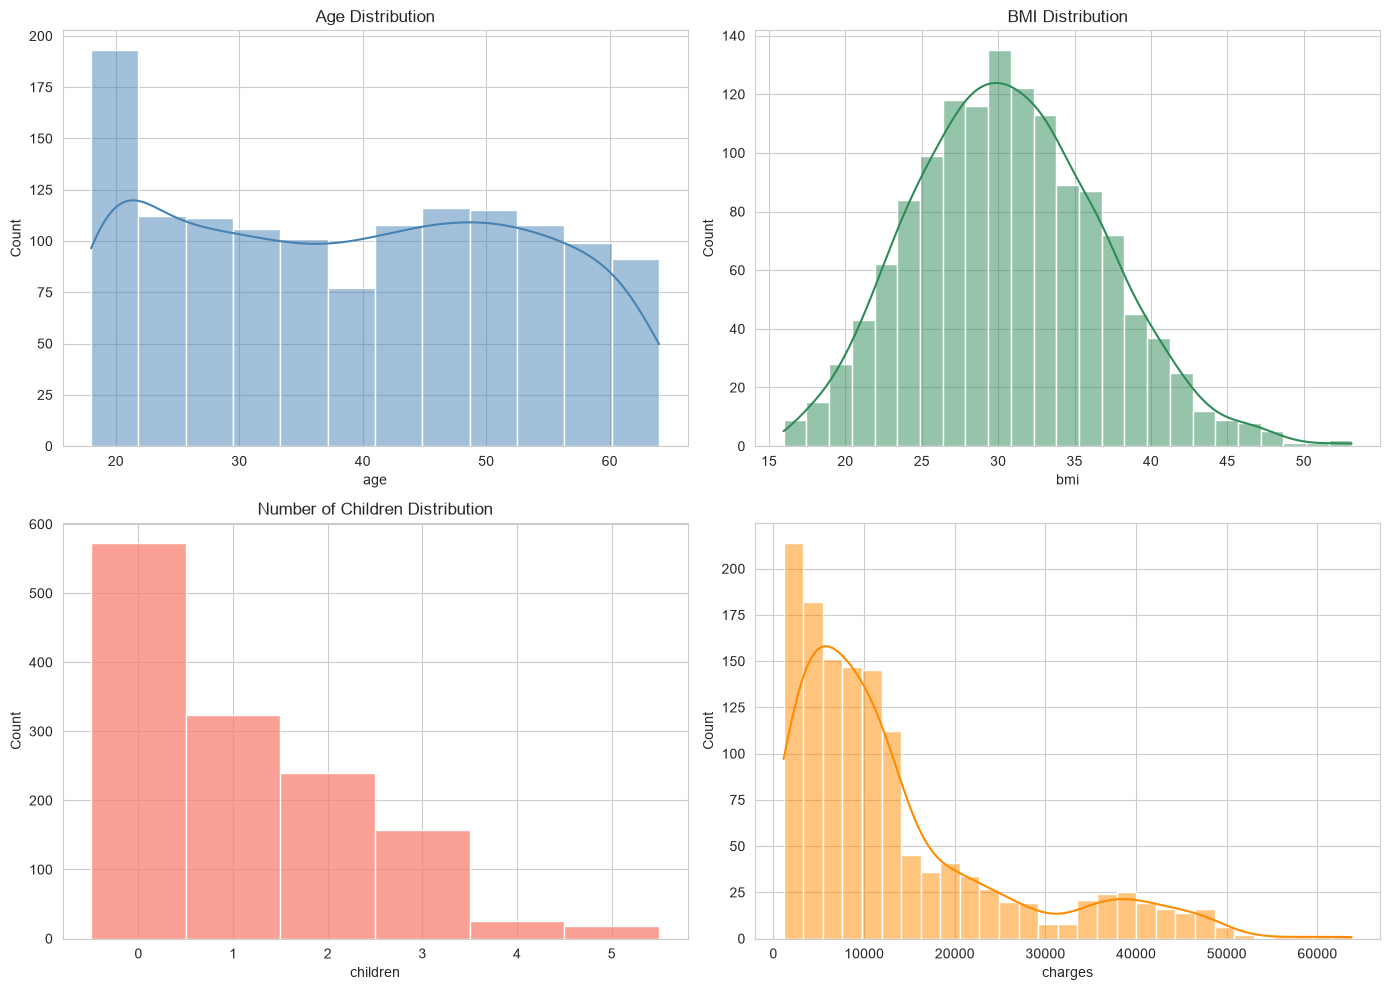

In [27]:
fig, axes = plt.subplots(2,2, figsize=(14,10))

sns.histplot(df["age"], kde=True, ax=axes[0,0], color="steelblue")
axes[0,0].set_title("Age Distribution")

sns.histplot(df["bmi"], kde=True, ax=axes[0,1], color="seagreen")
axes[0,1].set_title("BMI Distribution")

sns.histplot(df["children"], discrete=True, ax=axes[1,0], color="salmon")
axes[1,0].set_title("Number of Children Distribution")

sns.histplot(df["charges"], kde=True, ax=axes[1,1], color="darkorange")

axes[1,1].set_title("Charges Distribution")


plt.tight_layout()
plt.show()

In [28]:
 for col in ["bmi","charges"]:
     q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
     IQR = q3 - q1
     lower, upper = q1- 1.5 * IQR, q3 + 1.5 *IQR
     n_out = ((df[col] < lower) | (df[col]>upper)).sum()
     print(f"{col}: bounds = ({lower:.1f}, outliers = {n_out} ({n_out/len(df) * 100: .1f}%))")

bmi: bounds = (13.7, outliers = 9 ( 0.7%))
charges: bounds = (-13120.7, outliers = 139 ( 10.4%))


In [29]:
df.groupby("smoker")["charges"].agg("mean","std","count")

smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

In [32]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "underweight"
    elif bmi < 25:
        return "overweight"
    else:
        return "obese"

In [34]:
df["bmi_category"]=df["bmi"].apply(bmi_category)

In [35]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,obese
1,18,male,33.770,1,no,southeast,1725.55230,obese
2,28,male,33.000,3,no,southeast,4449.46200,obese
3,33,male,22.705,0,no,northwest,21984.47061,overweight
4,32,male,28.880,0,no,northwest,3866.85520,obese


In [36]:
df["bmi_category"].value_counts()

bmi_category
obese          1092
overweight      225
underweight      20
Name: count, dtype: int64

In [37]:
df.groupby("bmi_category")["charges"].mean().sort_values().round(2)

bmi_category
underweight     8852.20
overweight     10409.34
obese          13951.50
Name: charges, dtype: float64

In [43]:
df["log_charges"]=np.log(df["charges"])
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,obese,9.734176
1,18,male,33.770,1,no,southeast,1725.55230,obese,7.453302
2,28,male,33.000,3,no,southeast,4449.46200,obese,8.400538
3,33,male,22.705,0,no,northwest,21984.47061,overweight,9.998092
4,32,male,28.880,0,no,northwest,3866.85520,obese,8.260197


In [44]:
df["charges"].skew()

np.float64(1.5153909108403483)

In [45]:
df["log_charges"].skew()

np.float64(-0.08983863481292871)

In [46]:
df_model = pd.get_dummies(
    df,
    columns = ["sex", "smoker", "region", "bmi_category"],
    drop_first=True
)
print(df_model.columns.to_list())

['age', 'bmi', 'children', 'charges', 'log_charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_overweight', 'bmi_category_underweight']


In [47]:
df_model.head()

,age,bmi,children,charges,log_charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_overweight,bmi_category_underweight
0,19,27.900,0,16884.92400,9.734176,False,True,False,False,True,False,False
1,18,33.770,1,1725.55230,7.453302,True,False,False,True,False,False,False
2,28,33.000,3,4449.46200,8.400538,True,False,False,True,False,False,False
3,33,22.705,0,21984.47061,9.998092,True,False,True,False,False,True,False
4,32,28.880,0,3866.85520,8.260197,True,False,True,False,False,False,False


In [52]:
feature_cols = [c for c in df_model.columns if c not in ["charges","log_charges"]]
x=df_model[feature_cols]
y=df_model["log_charges"]

In [53]:
X_train, X_test, y_train, y_test= train_test_split(x,y, test_size=0.2)

In [57]:
y_test_real = np.exp(y_test)
candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05)
}

trained_models={}
metrics_rows=[]

for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    y_pred_log = model.predict(X_test)
    y_pred = np.exp(y_pred_log)

    r2 = r2_score(y_test_real, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse=np.sqrt(mean_squared_error(y_test_real,y_pred))

    trained_models[name]=model
    metrics_rows.append({"Model": name, "R2": r2, "MAE" : mae, "RMSE" : rmse})

    print(f"{name} -> R2:{r2:.4f} - MAE: {mae:.2f} - RMSE: {rmse:.2f}")

Linear Regression -> R2:0.3932 - MAE: 15037.10 - RMSE: 10228.18
Random Forest -> R2:0.8490 - MAE: 13714.20 - RMSE: 5102.69
Gradient Boosting -> R2:0.8346 - MAE: 13752.23 - RMSE: 5339.93


In [63]:
results = pd.DataFrame(metrics_rows).sort_values("R2", ascending=False).reset_index(drop=True)

In [64]:
results

,Model,R2,MAE,RMSE
0,Random Forest,0.848985,13714.200871,5102.688828
1,Gradient Boosting,0.834616,13752.232770,5339.928037
2,Linear Regression,0.393236,15037.096102,10228.184346


In [65]:
best_model_name = results.loc[0,"Model"]
best_model = trained_models[best_model_name]

In [66]:
best_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [ ]:
joblib.dump(best_model, "insurance_model.pkl")
joblib.dump(feature_cols,"model_features.pkl")
joblib.dump(best_model_name,"model_name.pkl")